# 4 — Ablation: does the forest need all 23 features, or one per family?

Notebook 2 feeds the forest every light-curve column. Several of those columns measure the
same physical quantity — `excess_var`, `intrinsic_std`, `intrinsic_rms` and `sigma_mad` are
four views of one scatter — and that redundancy is not free.

`max_features='sqrt'` makes the forest consider about six of the ~35 columns at each split.
A family with four near-duplicate members is therefore offered four times as often as a
singleton like `gp_jitter`: **split attention is allocated by family size, not by information
content.** Collapsing the families removes that bias.

Pulling the other way, redundant copies let the trees average over measurement noise in a
quantity, which a single representative throws away. The `family index` variant below is the
attempt to have both: one column per family, but built from all its members.

Four feature sets, all with the same nuisance block, the same forest, the same folds, and the
same held-out clusters as notebook 2 (`SEED = 0`):

| set | light-curve columns |
|---|---|
| nuisance only | none — the reference |
| all features | every FEATURE_SPEC column (= notebook 2's *full*) |
| family representative | the most reliable member of each family |
| family index | sign-aligned mean of z-scored ranks over each family's members |

**What would count as a result.** If *representative* or *index* matches *all features*, the
smaller model is the one to report — "six quantities carry the signal" is a much stronger
claim than "23 correlated columns do". If they fall clearly short, the redundancy was doing
real work and the extra columns stay.

In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath('.'))
import analysis_utils as A

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

GT = '/astro/users/cgwill/TESS_Cluster_Age_ML/GenerateTable_CGW/data'
CANDIDATES = [
    f'{GT}/cluster_table_Sep23_all_combos_le3sectors.pkl',
    f'{GT}/cluster_table_Sep21_3sectorcombos_real_nofallback.pkl',
]
TABLE = next(p for p in CANDIDATES if os.path.exists(p))
SEED = 0                      # same seed as notebook 2 -> same held-out clusters
print('using', os.path.basename(TABLE))
pd.set_option('display.width', 220)
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'axes.axisbelow': True,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})
COLOURS = {'MW': '#2a78d6', 'LMC': '#eb6834', 'SMC': '#1baf7a'}

using cluster_table_Sep23_all_combos_le3sectors.pkl


In [2]:
rows = A.load_rows(TABLE)
meta = A.cluster_metadata()
clusters = A.cluster_table(rows, meta=meta)

FEATURES  = [c for c, _, _ in A.feature_columns(rows)]
NUISANCES = [n for n, _, _ in A.NUISANCE_SPEC if n in clusters.columns]
y = clusters.age.values

# families from feature-feature structure only; age is never used (see analysis_utils)
reliability = A.feature_reliability(rows)
fam_df, fams, FAM_COLS = A.build_family_table(clusters, FEATURES, threshold=0.8,
                                              reliability=reliability)
REPS = sorted(fams.representative.unique())

X_nuis = A.design_matrix(clusters, NUISANCES, add_const=False)
X_all  = clusters[FEATURES].apply(pd.to_numeric, errors='coerce')
X_rep  = clusters[REPS].apply(pd.to_numeric, errors='coerce')
X_idx  = fam_df[FAM_COLS].apply(pd.to_numeric, errors='coerce')

print(f'{len(clusters)} clusters | {len(FEATURES)} features collapse to {len(REPS)} families')
display(fams.groupby('representative')
            .agg(n_members=('n_members', 'first'), mean_abs_rho=('mean_abs_rho', 'first'),
                 members=('feature', lambda s: ', '.join(s)))
            .sort_values('n_members', ascending=False).round(3))

17233 rows, 348 clusters from cluster_table_Sep23_all_combos_le3sectors.pkl
rows per cluster: median 3, max 409


348 clusters | 23 features collapse to 12 families


,n_members,mean_abs_rho,members
representative,,,
sigma_mad,5,0.926,"excess_var, intrinsic_std, sigma_mad, intrinsi..."
stetson_j_gap_aware,4,0.848,"vn_ratio_gap_aware, stetson_j_gap_aware, rn_al..."
LSP_peak_snr_rn,2,0.940,"LSP_peak_snr_at_diff, LSP_peak_snr_rn"
gp_rn_rms_band,2,0.997,"gp_rn_log10_S0, gp_rn_rms_band"
gp_rn_wn_ratio,2,0.829,"gp_rn_alpha_band, gp_rn_wn_ratio"
mean_median_offset,2,0.958,"gamma_p_sec, mean_median_offset"
LSP_peak_period_diff,1,1.000,LSP_peak_period_diff
g1_int_sec,1,1.000,g1_int_sec
gp_Q_strongest,1,1.000,gp_Q_strongest


In [3]:
def make_forest(seed=SEED):
    """Identical to notebook 2, so every number here is comparable with it."""
    return Pipeline([('impute', SimpleImputer(strategy='median')),
                     ('rf', RandomForestRegressor(n_estimators=600, min_samples_leaf=3,
                                                  max_features='sqrt', random_state=seed,
                                                  n_jobs=8))])

def cv_score(X, y, n_repeats=5, seed=SEED):
    cv = RepeatedKFold(n_splits=5, n_repeats=n_repeats, random_state=seed)
    sc = []
    for k, (tr, te) in enumerate(cv.split(X, y)):
        m = make_forest(seed + k).fit(X.iloc[tr], y[tr])
        p = m.predict(X.iloc[te])
        sc.append((r2_score(y[te], p), mean_absolute_error(y[te], p)))
    s = np.array(sc)
    return s[:, 0], s[:, 1]

def evaluate(sets, y_pool, hold_frames, y_hold, n_repeats=5):
    """Cross-validate each feature set on the pool, then score it once on the holdout."""
    out = []
    for label, Xp in sets.items():
        r2, mae = cv_score(Xp, y_pool, n_repeats=n_repeats)
        ph = make_forest(SEED).fit(Xp, y_pool).predict(hold_frames[label])
        out.append(dict(model=label, n_cols=Xp.shape[1], r2=r2.mean(), r2_sd=r2.std(),
                        mae=mae.mean(), holdout_r2=r2_score(y_hold, ph),
                        holdout_mae=mean_absolute_error(y_hold, ph)))
        print(f'{label:>28}: {Xp.shape[1]:3d} cols | CV R2 {r2.mean():+.3f} +/- {r2.std():.3f} | '
              f'holdout R2 {out[-1]["holdout_r2"]:+.3f}')
    return pd.DataFrame(out)

def plot_sets(df, title, baseline='nuisance only'):
    fig, ax = plt.subplots(figsize=(8.6, 0.55 * len(df) + 1.8))
    t = df.iloc[::-1]
    ax.barh(t.model, t.r2, xerr=t.r2_sd, color='#2a78d6', alpha=.85, label='cross-validated (pool)')
    ax.plot(t.holdout_r2, np.arange(len(t)), 'D', color='#eb6834', ms=7, label='held-out clusters')
    if baseline in set(df.model):
        ax.axvline(float(df.loc[df.model == baseline, 'r2'].iloc[0]), color='#5f5e5a', lw=1, ls='--')
    ax.axvline(0, color='#5f5e5a', lw=1)
    for i, row in enumerate(t.itertuples()):
        ax.text(max(row.r2, row.holdout_r2) + .012, i, f'{row.n_cols} cols',
                va='center', fontsize=9, color='#5f5e5a')
    ax.set(xlabel='R² (age, log years)')
    ax.set_title(title + '\ndashed line = nuisance-only baseline', loc='left', fontweight='bold')
    ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

## 1 · The four models

Everything is fit on the 80% CV pool; the held-out 20% is scored once, at the same time, so
the two columns of the figure below come from a single pass.

pool 278 clusters | holdout 70 clusters (mean age 8.19 vs 8.24)


               nuisance only:  10 cols | CV R2 +0.154 +/- 0.141 | holdout R2 +0.282


                all features:  33 cols | CV R2 +0.200 +/- 0.099 | holdout R2 +0.113


       family representative:  22 cols | CV R2 +0.217 +/- 0.098 | holdout R2 +0.208


                family index:  22 cols | CV R2 +0.234 +/- 0.093 | holdout R2 +0.161


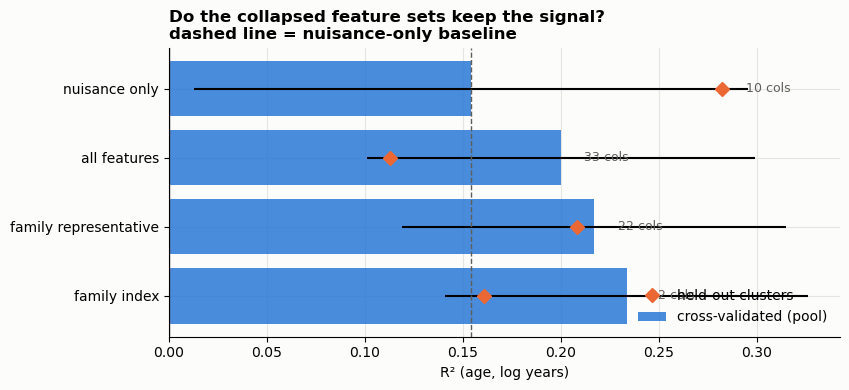

CONCLUSION —
  Gain over nuisance-only:  all features +0.046, representative +0.063, index +0.079 (CV).
  On the held-out clusters: -0.169 / -0.074 / -0.122.
  "family index" matches the full set to within 0.02 R2 using 22 columns instead of 33.
  Report the smaller model: the redundant columns were adding split opportunities,
  not information.


In [4]:
HOLD = A.holdout_by_cluster(clusters.name.values, y=y, frac=0.2, seed=SEED)
POOL = ~HOLD
y_p, y_h = y[POOL], y[HOLD]
print(f'pool {POOL.sum()} clusters | holdout {HOLD.sum()} clusters '
      f'(mean age {y_p.mean():.2f} vs {y_h.mean():.2f})')

def with_nuis(Xf):
    return pd.concat([X_nuis, Xf], axis=1) if Xf is not None else X_nuis

SETS = {'nuisance only':         None,
        'all features':          X_all,
        'family representative': X_rep,
        'family index':          X_idx}
pool_sets = {k: with_nuis(v)[POOL] for k, v in SETS.items()}
hold_sets = {k: with_nuis(v)[HOLD] for k, v in SETS.items()}

res = evaluate(pool_sets, y_p, hold_sets, y_h)
plot_sets(res, 'Do the collapsed feature sets keep the signal?')

base = float(res.loc[res.model == 'nuisance only', 'r2'].iloc[0])
g = {r.model: r.r2 - base for r in res.itertuples()}
gh = {r.model: r.holdout_r2 - float(res.loc[res.model == 'nuisance only', 'holdout_r2'].iloc[0])
      for r in res.itertuples()}
best_small = max(['family representative', 'family index'], key=lambda k: g[k])
print('CONCLUSION —')
print(f'  Gain over nuisance-only:  all features {g["all features"]:+.3f}, '
      f'representative {g["family representative"]:+.3f}, index {g["family index"]:+.3f} (CV).')
print(f'  On the held-out clusters: {gh["all features"]:+.3f} / '
      f'{gh["family representative"]:+.3f} / {gh["family index"]:+.3f}.')
if g[best_small] >= g['all features'] - 0.02:
    print(f'  "{best_small}" matches the full set to within 0.02 R2 using '
          f'{pool_sets[best_small].shape[1]} columns instead of {pool_sets["all features"].shape[1]}.')
    print('  Report the smaller model: the redundant columns were adding split opportunities,')
    print('  not information.')
else:
    print(f'  Collapsing costs {g["all features"] - g[best_small]:+.3f} R2. The redundant members')
    print('  were averaging down measurement noise, so keep the full set and rely on block')
    print('  permutation (notebook 2) rather than column pruning for interpretation.')

## 2 · Per-quantity importance

With one column per family, permutation importance is per *quantity* and needs no blocking —
each bar is a physical measurement, not an arbitrary member of a correlated group.

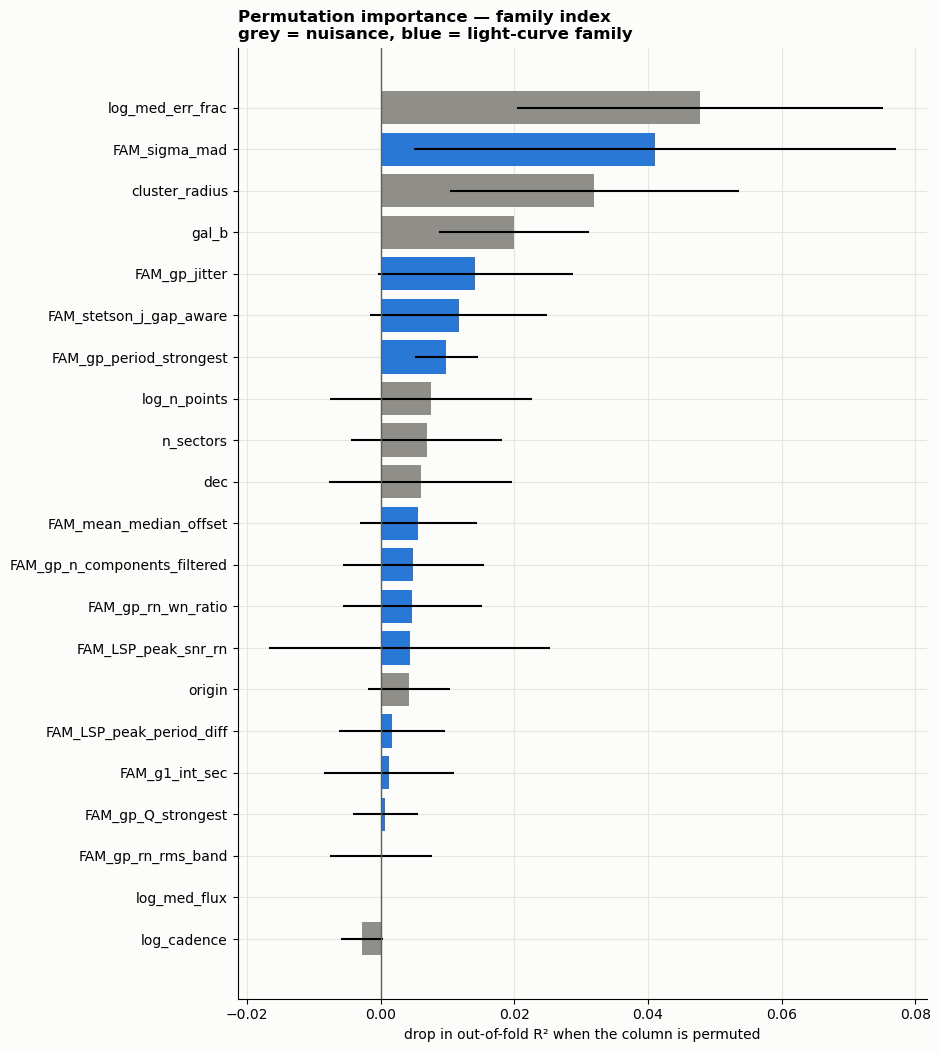

CONCLUSION —
  2 of 12 light-curve families have an importance larger than their own
  fold-to-fold scatter: sigma_mad, gp_period_strongest.
  Summed importance — light curve +0.1003 vs nuisance +0.1218.
  These are single columns, so unlike notebook 2 no blocking is needed and nothing is
  hidden by a correlated twin still carrying the information.


In [5]:
from collections import defaultdict
X_use = pool_sets[best_small]
Xh_use = hold_sets[best_small]
cv = RepeatedKFold(n_splits=5, n_repeats=2, random_state=SEED)
imp = defaultdict(list)
rng = np.random.default_rng(SEED)
for k, (tr, te) in enumerate(cv.split(X_use, y_p)):
    m = make_forest(SEED + k).fit(X_use.iloc[tr], y_p[tr])
    Xte, yte = X_use.iloc[te], y_p[te]
    b = r2_score(yte, m.predict(Xte))
    origin_cols = [c for c in X_use.columns if c.startswith('origin_')]
    blocks = {c: [c] for c in X_use.columns if c not in origin_cols}
    if origin_cols:
        blocks['origin'] = origin_cols
    for name, cols in blocks.items():
        d = []
        for _ in range(6):
            Xp = Xte.copy()
            Xp[cols] = Xp[cols].to_numpy()[rng.permutation(len(Xp))]
            d.append(b - r2_score(yte, m.predict(Xp)))
        imp[name].append(np.mean(d))

impdf = pd.DataFrame({'column': list(imp), 'importance': [np.mean(v) for v in imp.values()],
                      'sd': [np.std(v) for v in imp.values()]})
impdf['kind'] = np.where(impdf.column.str.replace('FAM_', '', regex=False).isin(FEATURES + REPS),
                         'light curve', 'nuisance')
impdf = impdf.sort_values('importance', ascending=False)

fig, ax = plt.subplots(figsize=(9.5, 0.42 * len(impdf) + 1.8))
t = impdf.iloc[::-1]
ax.barh(t.column, t.importance, xerr=t.sd,
        color=np.where(t.kind == 'nuisance', '#8f8e88', '#2a78d6'))
ax.axvline(0, color='#5f5e5a', lw=1)
ax.set(xlabel='drop in out-of-fold R² when the column is permuted')
ax.set_title(f'Permutation importance — {best_small}\ngrey = nuisance, blue = light-curve family',
             loc='left', fontweight='bold')
plt.tight_layout(); plt.show()

lc = impdf[impdf.kind == 'light curve']
nu = impdf[impdf.kind == 'nuisance']
pos = lc[lc.importance > lc.sd]
print('CONCLUSION —')
print(f'  {len(pos)} of {len(lc)} light-curve families have an importance larger than their own')
print(f'  fold-to-fold scatter: {", ".join(pos.column.str.replace("FAM_", "", regex=False)) or "none"}.')
print(f'  Summed importance — light curve {lc.importance.sum():+.4f} vs nuisance {nu.importance.sum():+.4f}.')
print('  These are single columns, so unlike notebook 2 no blocking is needed and nothing is')
print('  hidden by a correlated twin still carrying the information.')

## 3 · Result table

In [6]:
res.to_csv('results_rf_family_ablation.csv', index=False)
impdf.to_csv('results_rf_family_importances.csv', index=False)
display(res.round(3))
print('wrote results_rf_family_ablation.csv, results_rf_family_importances.csv')
print()
print('CONCLUSION —')
print(f'  {len(FEATURES)} light-curve columns describe {len(REPS)} distinct quantities.')
print(f'  Best small model: {best_small} at CV R2 {float(res.loc[res.model == best_small, "r2"].iloc[0]):+.3f} '
      f'vs {float(res.loc[res.model == "all features", "r2"].iloc[0]):+.3f} for all features.')
print('  Compare holdout_r2 against notebook 2 (results_random_forest.csv) — same clusters,')
print('  same forest, same seed, so the difference is the feature set alone.')

,model,n_cols,r2,r2_sd,mae,holdout_r2,holdout_mae
0,nuisance only,10,0.154,0.141,0.470,0.282,0.516
1,all features,33,0.200,0.099,0.458,0.113,0.554
2,family representative,22,0.217,0.098,0.451,0.208,0.540
3,family index,22,0.234,0.093,0.449,0.161,0.547


wrote results_rf_family_ablation.csv, results_rf_family_importances.csv

CONCLUSION —
  23 light-curve columns describe 12 distinct quantities.
  Best small model: family index at CV R2 +0.234 vs +0.200 for all features.
  Compare holdout_r2 against notebook 2 (results_random_forest.csv) — same clusters,
  same forest, same seed, so the difference is the feature set alone.
